# D280mm-focus-guide6p5um 四方向 PSF 生成与检查

这个 notebook 以原始 bundle `/home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um/sim_psf_images.pkl` 为起点，生成 3 个对称版本，再加上原始版本，一共得到 4 个 PSF bundle。

四个 bundle 对应的导星探测器位置约定如下：

- `guide_right`：焦平面右侧导星探测器；原始 PSF bundle 对应这个方向。
- `guide_left`：焦平面左侧导星探测器；由原始 bundle 左右镜像得到。
- `guide_top`：焦平面上侧导星探测器；由原始 bundle 旋转得到。
- `guide_bottom`：焦平面下侧导星探测器；由原始 bundle 旋转得到。

生成规则很简单：

- `guide_right`：保持原始图像不变。
- `guide_left`：对强度图做左右镜像。
- `guide_top`：对强度图做顺时针 90° 旋转。
- `guide_bottom`：对强度图做逆时针 90° 旋转。

下面的代码会：

1. 读取原始 PSF bundle。
2. 生成 3 个对称版本并写入对应目录。
3. 分别打印四个 PSF 的名称和路径。
4. 画出四个 PSF 的图像、curve of growth、EE90 半径和 FWHM。

In [3]:
import copy
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import PowerNorm
from matplotlib.patches import Circle

SOURCE_BUNDLE = Path("/home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um/sim_psf_images.pkl")
BASE_DIR = SOURCE_BUNDLE.parent.parent
FIELD_ID = 7
SUBPIXEL_GRID = 1


def _identity(image: np.ndarray) -> np.ndarray:
    return image


def _flip_left_right(image: np.ndarray) -> np.ndarray:
    return np.flip(image, axis=1)


def _rotate_clockwise(image: np.ndarray) -> np.ndarray:
    return np.rot90(image, k=-1)


def _rotate_counterclockwise(image: np.ndarray) -> np.ndarray:
    return np.rot90(image, k=1)


BUNDLE_SPECS = {
    "guide_right": {
        "transform": _identity,
        "detector_position": "focal-plane right side",
        "detector_note": "original bundle",
    },
    "guide_left": {
        "transform": _flip_left_right,
        "detector_position": "focal-plane left side",
        "detector_note": "left-right mirror of the original bundle",
    },
    "guide_top": {
        "transform": _rotate_clockwise,
        "detector_position": "focal-plane top side",
        "detector_note": "90° clockwise rotation of the original bundle",
    },
    "guide_bottom": {
        "transform": _rotate_counterclockwise,
        "detector_position": "focal-plane bottom side",
        "detector_note": "90° counterclockwise rotation of the original bundle",
    },
}


def parse_pixel_size_um(pixel_diameter: str | float | int) -> float:
    text = str(pixel_diameter).strip().lower().replace("μ", "u")
    if text.endswith("um"):
        text = text[:-2].strip()
    return float(text)


def load_bundle(path: Path) -> dict:
    with path.open("rb") as handle:
        return pickle.load(handle)


def save_transformed_bundle(source_bundle: dict, target_path: Path, transform) -> None:
    payload = copy.deepcopy(source_bundle)
    for field_id, field_entries in payload["images"].items():
        for subpixel_grid, planes in list(field_entries.items()):
            planes = np.asarray(planes)
            if planes.shape[0] != 3:
                raise ValueError(f"Unexpected plane shape for field {field_id}, grid {subpixel_grid}: {planes.shape}")
            x_grid, y_grid, intensity = planes
            transformed = transform(np.asarray(intensity, dtype=np.float64))
            field_entries[subpixel_grid] = np.stack([x_grid, y_grid, transformed], axis=0)

    target_path.parent.mkdir(parents=True, exist_ok=True)
    with target_path.open("wb") as handle:
        pickle.dump(payload, handle, protocol=pickle.HIGHEST_PROTOCOL)


def compute_ee90_radius_pix(x_grid: np.ndarray, y_grid: np.ndarray, intensity: np.ndarray):
    radius_pix = np.sqrt(x_grid * x_grid + y_grid * y_grid)
    order = np.argsort(radius_pix, axis=None)
    sorted_radius = radius_pix.ravel()[order]
    sorted_flux = intensity.ravel()[order]
    encircled = np.cumsum(sorted_flux)
    ee90_radius_pix = float(np.interp(0.9, encircled, sorted_radius))
    return ee90_radius_pix, sorted_radius, encircled


def compute_fwhm_pix(x_grid: np.ndarray, y_grid: np.ndarray, intensity: np.ndarray, bin_width: float = 0.1):
    peak_index = np.unravel_index(np.argmax(intensity), intensity.shape)
    peak_x = float(x_grid[peak_index])
    peak_y = float(y_grid[peak_index])
    radius_pix = np.sqrt((x_grid - peak_x) * (x_grid - peak_x) + (y_grid - peak_y) * (y_grid - peak_y))
    r_max = float(radius_pix.max())
    bins = np.arange(0.0, r_max + bin_width, bin_width)
    if len(bins) < 3:
        bins = np.linspace(0.0, r_max, 10)
    binned_sum, edges = np.histogram(radius_pix.ravel(), bins=bins, weights=intensity.ravel())
    binned_count, _ = np.histogram(radius_pix.ravel(), bins=bins)
    radial_profile = binned_sum / np.maximum(binned_count, 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    half_max = 0.5 * float(intensity.max())
    below = np.where(radial_profile <= half_max)[0]
    if len(below) == 0:
        fwhm_pix = float(2.0 * centers[-1])
    else:
        idx = int(below[0])
        if idx == 0:
            r_half = float(centers[0])
        else:
            x1, x2 = float(centers[idx - 1]), float(centers[idx])
            y1, y2 = float(radial_profile[idx - 1]), float(radial_profile[idx])
            if y2 == y1:
                r_half = x2
            else:
                r_half = x1 + (half_max - y1) * (x2 - x1) / (y2 - y1)
        fwhm_pix = float(2.0 * r_half)

    return fwhm_pix, centers, radial_profile, (peak_x, peak_y)


def load_or_build_bundle(bundle_name: str, spec: dict, source_bundle: dict) -> Path:
    target_dir = BASE_DIR / f"D280mm-focus-guide6p5um-{bundle_name}"
    target_path = target_dir / "sim_psf_images.pkl"
    if not target_path.exists():
        save_transformed_bundle(source_bundle, target_path, spec["transform"])
    return target_path


def plot_one_bundle(ax_image, ax_growth, ax_text, bundle_name: str, bundle_path: Path, spec: dict):
    bundle = load_bundle(bundle_path)
    field = bundle["images"][FIELD_ID][SUBPIXEL_GRID]
    x_grid, y_grid, intensity = np.asarray(field, dtype=np.float64)
    intensity = intensity / float(np.sum(intensity))
    ee90_radius_pix, radius_samples_pix, encircled_energy = compute_ee90_radius_pix(x_grid, y_grid, intensity)
    fwhm_pix, _, _, peak_xy = compute_fwhm_pix(x_grid, y_grid, intensity)
    pixel_size_um = parse_pixel_size_um(bundle["pixel_diameter"])
    peak_index = np.unravel_index(np.argmax(intensity), intensity.shape)
    detector_position = spec["detector_position"]
    detector_note = spec["detector_note"]

    extent = [float(x_grid.min()), float(x_grid.max()), float(y_grid.min()), float(y_grid.max())]
    image = ax_image.imshow(
        intensity,
        origin="lower",
        extent=extent,
        cmap="magma",
        norm=PowerNorm(gamma=0.35, vmin=0.0, vmax=float(intensity.max())),
    )
    ax_image.add_patch(Circle((0.0, 0.0), ee90_radius_pix, fill=False, color="cyan", linewidth=1.8))
    ax_image.scatter([peak_xy[0]], [peak_xy[1]], marker="x", s=60, color="white", linewidths=1.5)
    ax_image.set_aspect("equal")
    ax_image.set_xlabel("x [pixel]")
    ax_image.set_ylabel("y [pixel]")
    ax_image.set_title(f"{bundle_name} | PSF image", fontsize=11)
    ax_image.text(
        0.03,
        0.97,
        f"Field ID {FIELD_ID}\nSubpixel {SUBPIXEL_GRID}x{SUBPIXEL_GRID}\nEE90 = {ee90_radius_pix:.3f} pix\nFWHM = {fwhm_pix:.3f} pix",
        transform=ax_image.transAxes,
        va="top",
        ha="left",
        color="white",
        fontsize=9,
        bbox={"facecolor": "black", "alpha": 0.45, "edgecolor": "none", "pad": 4},
    )
    plt.colorbar(image, ax=ax_image, fraction=0.046, pad=0.04, label="Normalized intensity")

    ax_growth.plot(radius_samples_pix, encircled_energy, color="tab:blue", linewidth=1.8)
    ax_growth.axhline(0.9, color="tab:red", linestyle="--", linewidth=1.2)
    ax_growth.axvline(ee90_radius_pix, color="tab:red", linestyle="--", linewidth=1.2)
    ax_growth.scatter([ee90_radius_pix], [0.9], color="tab:red", zorder=3)
    ax_growth.set_title("Curve of growth", fontsize=11)
    ax_growth.set_xlabel("Radius [pixel]")
    ax_growth.set_ylabel("Cumulative flux")
    ax_growth.set_xlim(left=0.0)
    ax_growth.set_ylim(0.0, 1.01)
    ax_growth.set_box_aspect(1.0)
    ax_growth.grid(True, alpha=0.25)
    ax_growth.annotate(
        f"EE90 = {ee90_radius_pix:.3f} pix\n= {ee90_radius_pix * pixel_size_um:.2f} um",
        xy=(ee90_radius_pix, 0.9),
        xytext=(0.56, 0.16),
        textcoords="axes fraction",
        arrowprops={"arrowstyle": "->", "color": "tab:red", "lw": 1.0},
        fontsize=9,
        color="tab:red",
    )

    ax_text.axis("off")
    ax_text.text(
        0.0,
        1.0,
        (
            f"Bundle name: {bundle_name}\n"
            f"Bundle path: {bundle_path}\n"
            f"Detector position: {detector_position}\n"
            f"Detector note: {detector_note}\n"
            f"Pixel diameter: {pixel_size_um:.2f} um\n"
            f"Field ID: {FIELD_ID}\n"
            f"Subpixel grid: {SUBPIXEL_GRID}x{SUBPIXEL_GRID}\n"
            f"Peak pixel index: {peak_index}\n"
            f"Peak location: ({peak_xy[0]:.1f}, {peak_xy[1]:.1f})\n"
            f"EE90 radius: {ee90_radius_pix:.3f} pix = {ee90_radius_pix * pixel_size_um:.2f} um\n"
            f"FWHM: {fwhm_pix:.3f} pix = {fwhm_pix * pixel_size_um:.2f} um\n"
        ),
        va="top",
        ha="left",
        fontsize=10,
        family="monospace",
        linespacing=1.45,
    )

    return {
        "bundle_name": bundle_name,
        "bundle_path": str(bundle_path),
        "peak_xy": peak_xy,
        "ee90_radius_pix": ee90_radius_pix,
        "fwhm_pix": fwhm_pix,
    }

In [4]:
source_bundle = load_bundle(SOURCE_BUNDLE)
generated_paths = {}

print("原始 bundle: guide_right 对应右侧导星探测器")
print(f"原始文件: {SOURCE_BUNDLE}")
print()

for bundle_name, spec in BUNDLE_SPECS.items():
    bundle_path = load_or_build_bundle(bundle_name, spec, source_bundle)
    generated_paths[bundle_name] = bundle_path
    print(f"{bundle_name}: {bundle_path}")
    print(f"  detector position: {spec['detector_position']}")
    print(f"  generation rule: {spec['detector_note']}")
    print()

原始 bundle: guide_right 对应右侧导星探测器
原始文件: /home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um/sim_psf_images.pkl

guide_right: /home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um-guide_right/sim_psf_images.pkl
  detector position: focal-plane right side
  generation rule: original bundle

guide_left: /home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um-guide_left/sim_psf_images.pkl
  detector position: focal-plane left side
  generation rule: left-right mirror of the original bundle

guide_top: /home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um-guide_top/sim_psf_images.pkl
  detector position: focal-plane top side
  generation rule: 90° clockwise rotation of the original bundle

guide_bottom: /home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um-guide_bottom/sim_psf_images.pkl
  detector position: focal-plane bottom side
  generation rule: 90° counterclockwise rotation of the original bundle



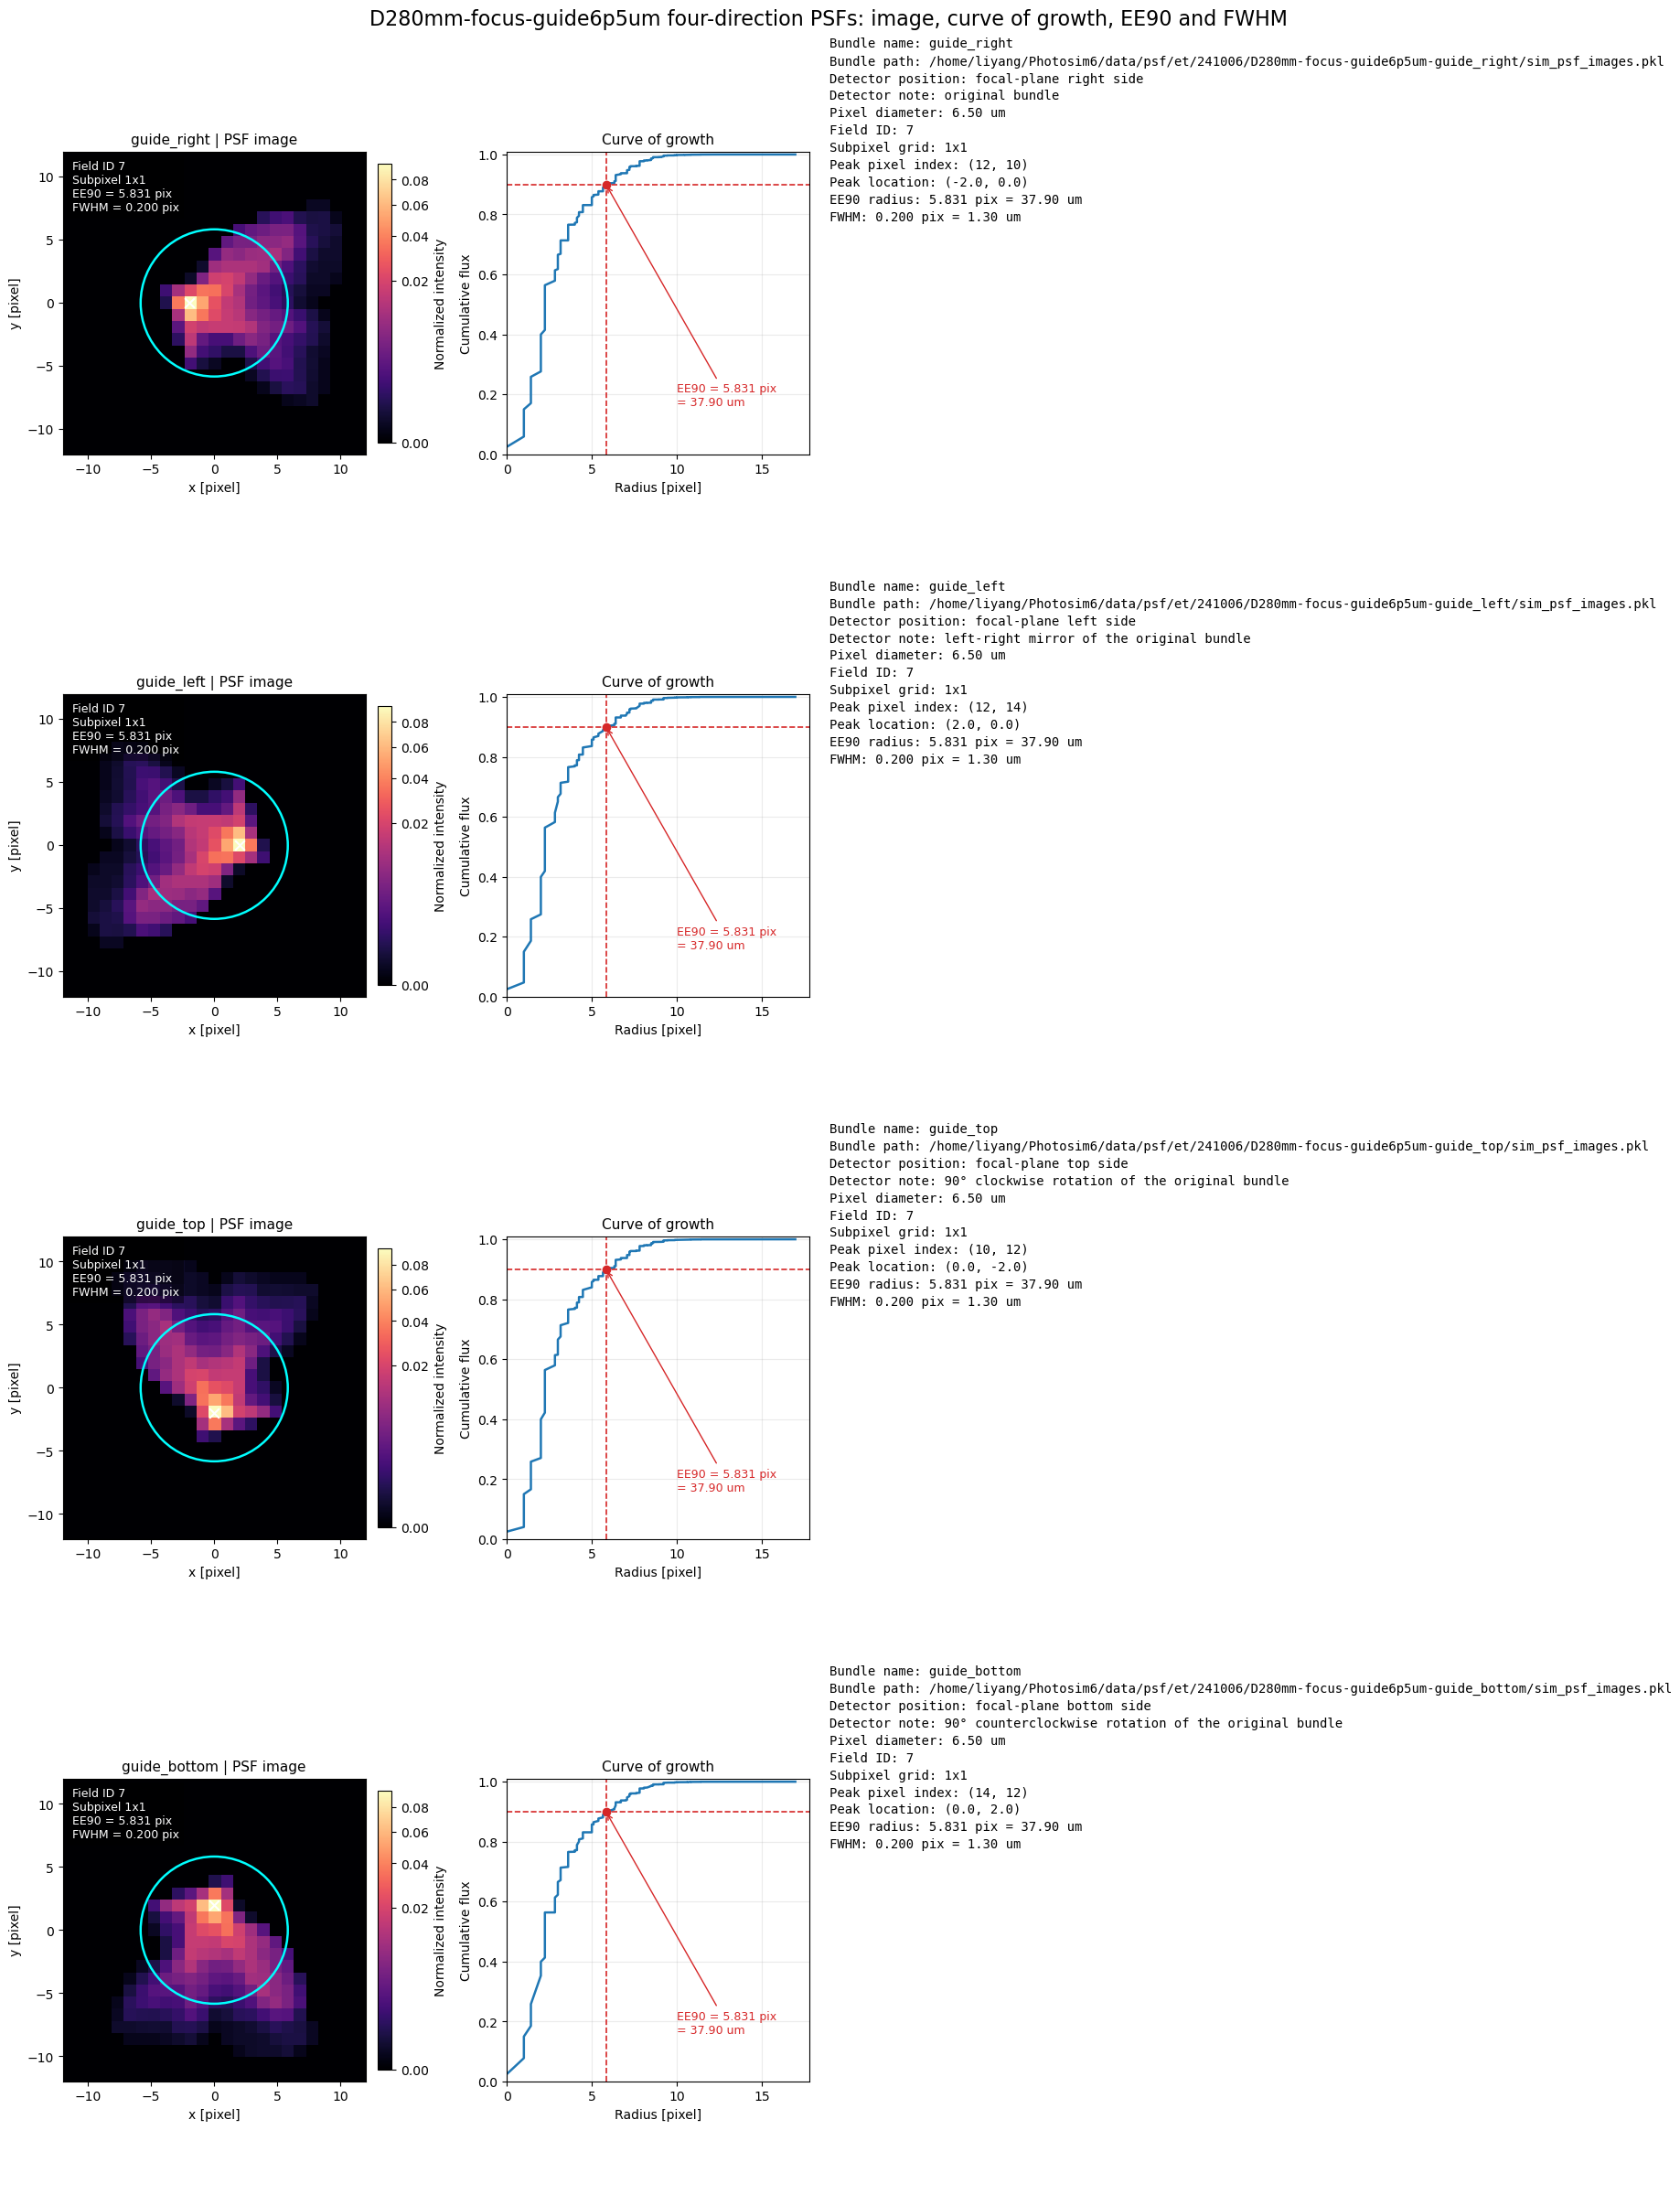

[{'bundle_name': 'guide_right',
  'bundle_path': '/home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um-guide_right/sim_psf_images.pkl',
  'peak_xy': (-2.0, 0.0),
  'ee90_radius_pix': 5.830951894845301,
  'fwhm_pix': 0.2},
 {'bundle_name': 'guide_left',
  'bundle_path': '/home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um-guide_left/sim_psf_images.pkl',
  'peak_xy': (2.0, 0.0),
  'ee90_radius_pix': 5.830951894845301,
  'fwhm_pix': 0.2},
 {'bundle_name': 'guide_top',
  'bundle_path': '/home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um-guide_top/sim_psf_images.pkl',
  'peak_xy': (0.0, -2.0),
  'ee90_radius_pix': 5.830951894845301,
  'fwhm_pix': 0.2},
 {'bundle_name': 'guide_bottom',
  'bundle_path': '/home/liyang/Photosim6/data/psf/et/241006/D280mm-focus-guide6p5um-guide_bottom/sim_psf_images.pkl',
  'peak_xy': (0.0, 2.0),
  'ee90_radius_pix': 5.830951894845301,
  'fwhm_pix': 0.2}]

In [5]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(18, 24), constrained_layout=True)
summary_rows = []

for row, bundle_name in enumerate(("guide_right", "guide_left", "guide_top", "guide_bottom")):
    spec = BUNDLE_SPECS[bundle_name]
    row_summary = plot_one_bundle(
        axes[row, 0],
        axes[row, 1],
        axes[row, 2],
        bundle_name,
        generated_paths[bundle_name],
        spec,
    )
    summary_rows.append(row_summary)

fig.suptitle(
    "D280mm-focus-guide6p5um four-direction PSFs: image, curve of growth, EE90 and FWHM",
    fontsize=16,
)
plt.show()

summary_rows

## 运行结果说明

如果你在仿真脚本里只想切换 PSF 方向，通常只需要替换 `sim_psf_images.pkl` 所在目录，不需要改文件名。这个 notebook 里生成的四个目录可以直接对应四片导星探测器：

- `D280mm-focus-guide6p5um-guide_right`
- `D280mm-focus-guide6p5um-guide_left`
- `D280mm-focus-guide6p5um-guide_top`
- `D280mm-focus-guide6p5um-guide_bottom`

## 凌星望远镜聚焦/离焦 guide6p5um PSF 与 EE90

这一节读取 `/home/liyang/ET7/Photsim7-data/psf/et/241006` 下所有以 `-guide6p5um` 结尾的 PSF bundle，并固定使用 `field=7`。图像显示 `subpixel=1` 的像素级 PSF；EE90 默认使用同一 field 下最高采样层 `subpixel=41` 来量测，避免粗像素网格让不同 PSF 的 EE90 落到同一个离散半径上。

输出表同时列出 `subpixel=1` 和 `subpixel=41` 的 EE90，并检查几组可疑 bundle 在 `field=7` 下是否逐元素完全相同。

Found 7 guide6p5um PSF bundles:
  /home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-defocus(-0.05mm)-guide6p5um/sim_psf_images.pkl
  /home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-defocus(-0.03mm)-guide6p5um/sim_psf_images.pkl
  /home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-defocus(-0.01mm)-guide6p5um/sim_psf_images.pkl
  /home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-focus-guide6p5um/sim_psf_images.pkl
  /home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-defocus(+0.01mm)-guide6p5um/sim_psf_images.pkl
  /home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-defocus(+0.03mm)-guide6p5um/sim_psf_images.pkl
  /home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-defocus(+0.05mm)-guide6p5um/sim_psf_images.pkl


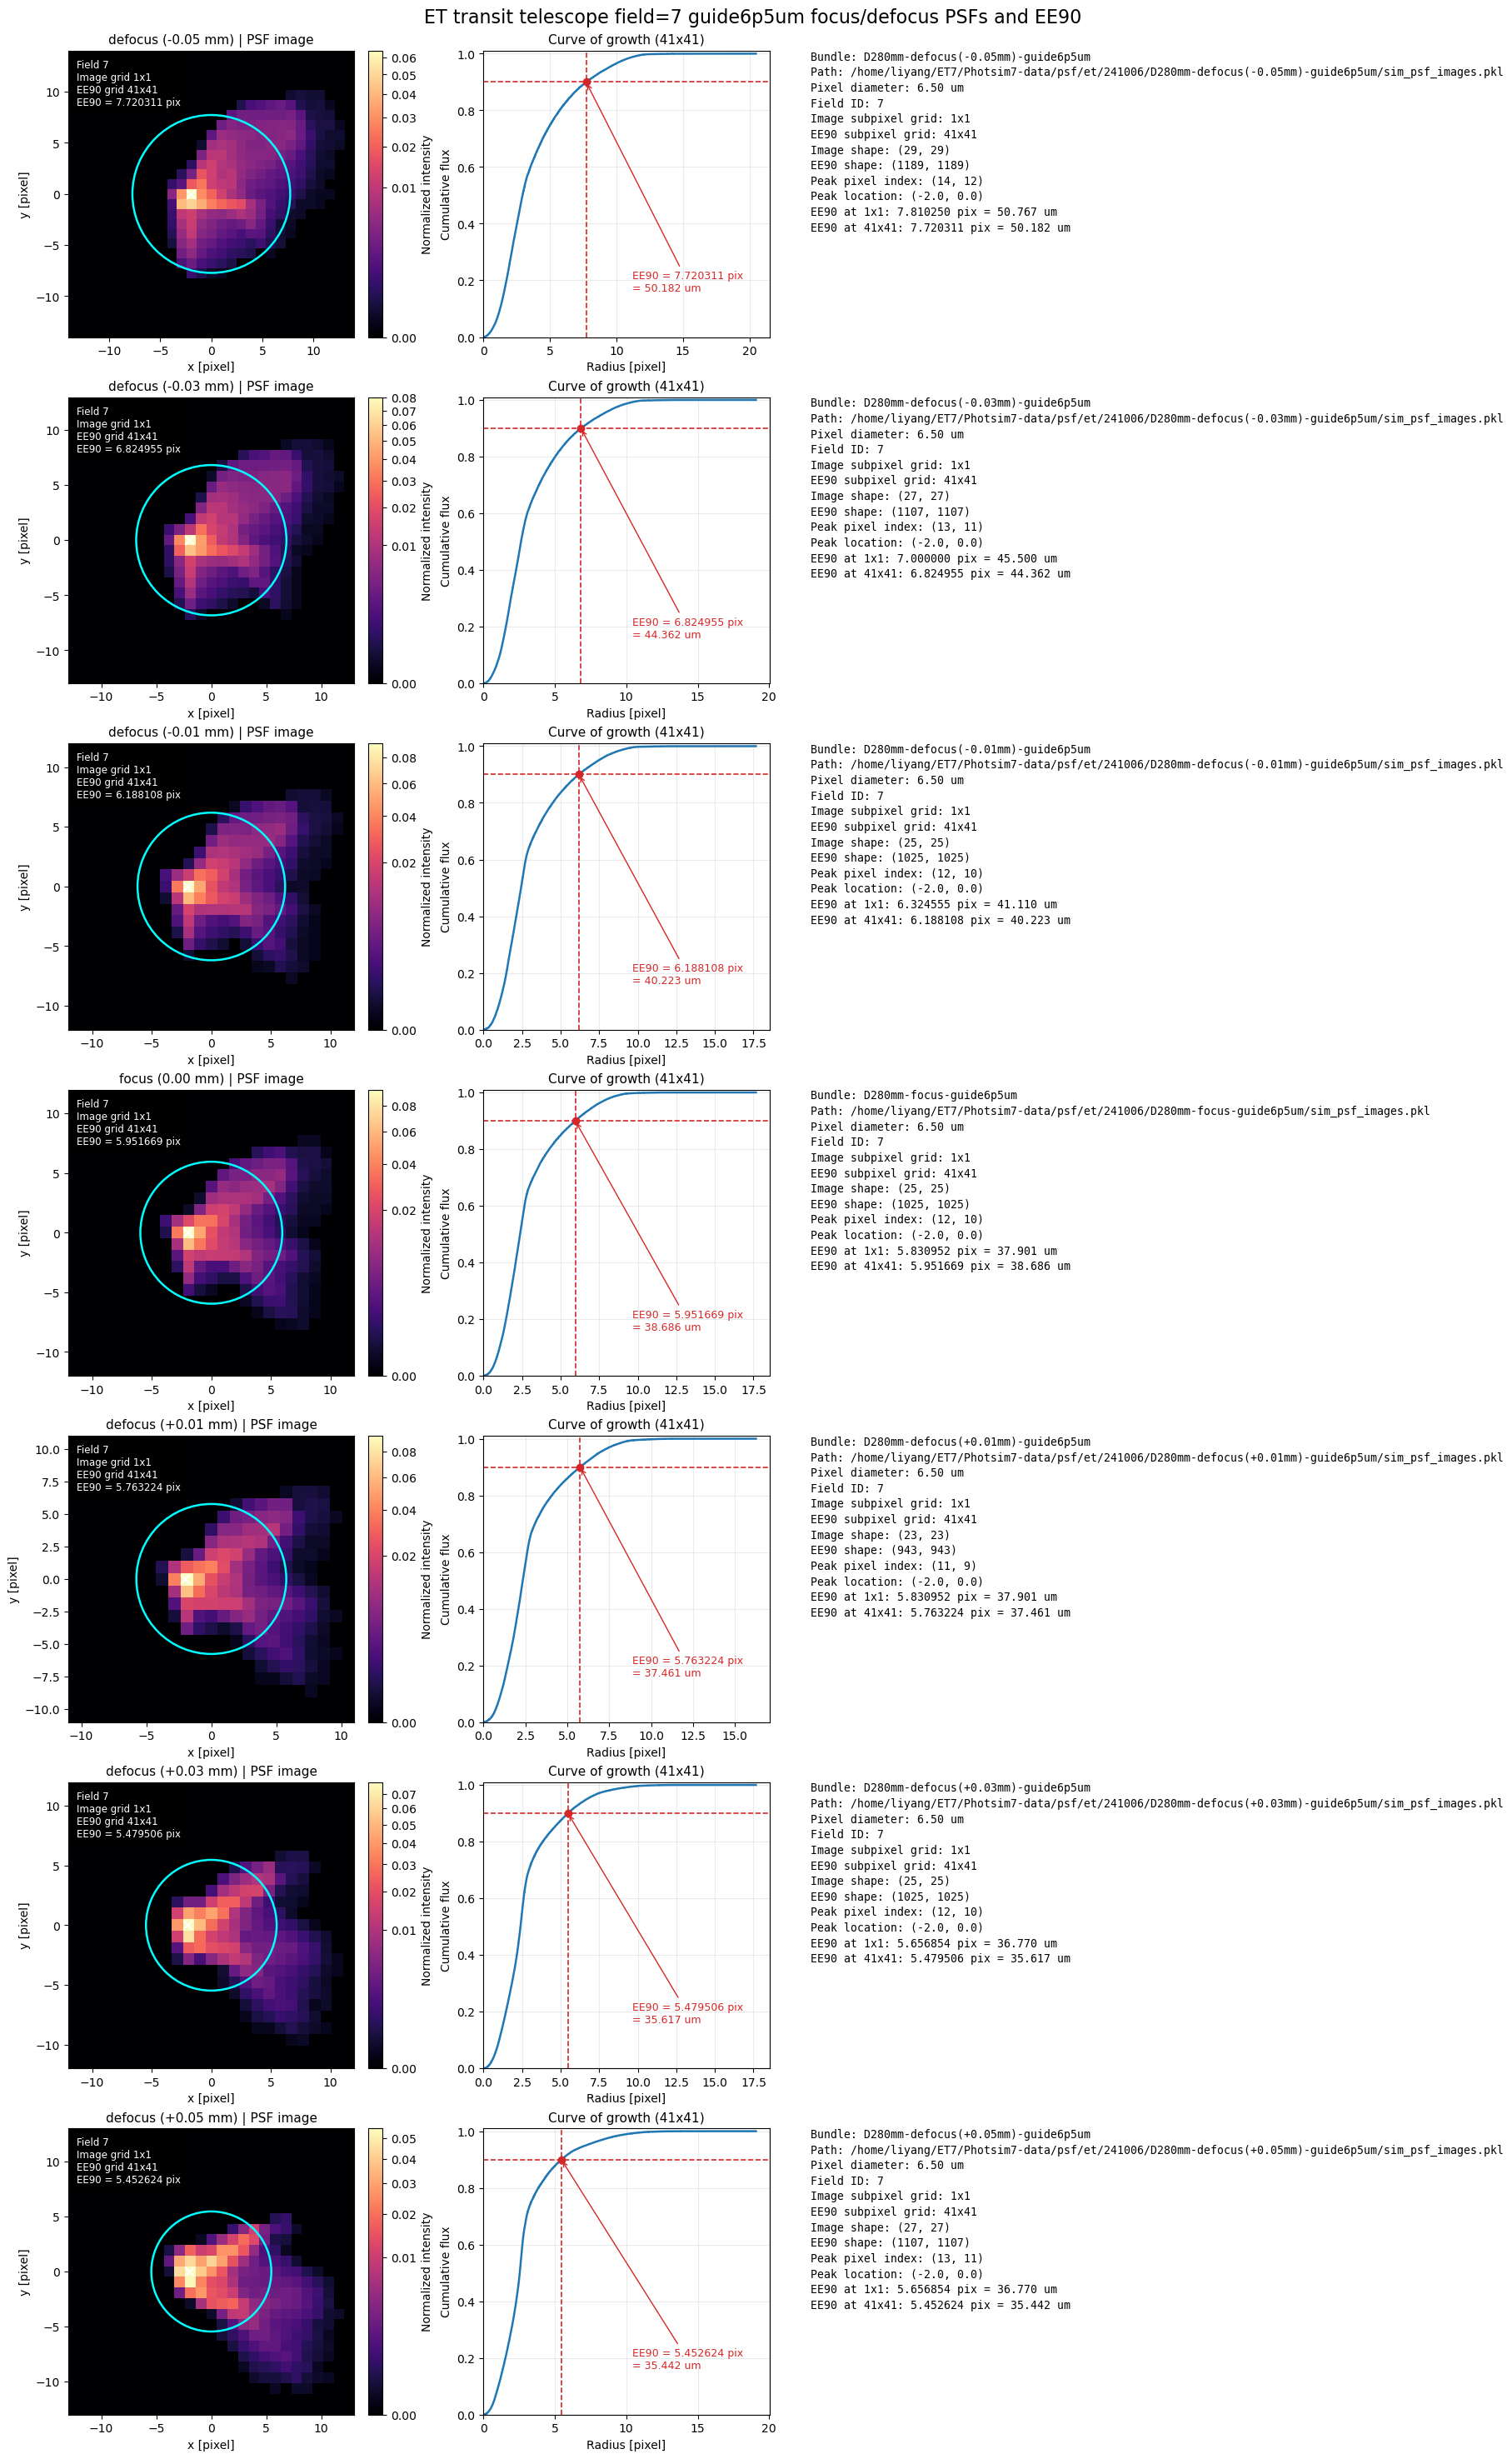


Field=7 exact-equality checks for suspicious pairs:
guide focus vs +0.01: all planes equal=False, all intensity equal=False, 1x1 EE90=5.830951895 vs 5.830951895, 41x41 EE90=5.951669036 vs 5.763224135
guide +0.03 vs +0.05: all planes equal=False, all intensity equal=False, 1x1 EE90=5.656854249 vs 5.656854249, 41x41 EE90=5.479505852 vs 5.452624054
original focus vs +0.01: all planes equal=False, all intensity equal=False, 1x1 EE90=4.000000000 vs 3.605551275, 41x41 EE90=3.868756939 vs 3.744438467
original +0.03 vs +0.05: all planes equal=False, all intensity equal=False, 1x1 EE90=3.605551275 vs 3.605551275, 41x41 EE90=3.561309554 vs 3.544985607


{'focus_defocus_summary_rows': [{'bundle': 'D280mm-defocus(-0.05mm)-guide6p5um',
   'focus_offset_mm': -0.05,
   'field_id': 7,
   'image_subpixel_grid': 1,
   'ee90_subpixel_grid': 41,
   'image_shape': (29, 29),
   'ee90_shape': (1189, 1189),
   'peak_xy': (-2.0, 0.0),
   'ee90_pix_1x1': 7.810249675906654,
   'ee90_um_1x1': 50.76662289339325,
   'ee90_pix_41x41': 7.720311193930375,
   'ee90_um_41x41': 50.18202276054743,
   'path': '/home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-defocus(-0.05mm)-guide6p5um/sim_psf_images.pkl'},
  {'bundle': 'D280mm-defocus(-0.03mm)-guide6p5um',
   'focus_offset_mm': -0.03,
   'field_id': 7,
   'image_subpixel_grid': 1,
   'ee90_subpixel_grid': 41,
   'image_shape': (27, 27),
   'ee90_shape': (1107, 1107),
   'peak_xy': (-2.0, 0.0),
   'ee90_pix_1x1': 7.0,
   'ee90_um_1x1': 45.5,
   'ee90_pix_41x41': 6.82495506082252,
   'ee90_um_41x41': 44.36220789534638,
   'path': '/home/liyang/ET7/Photsim7-data/psf/et/241006/D280mm-defocus(-0.03mm)-guide6p5um/

In [7]:
import pickle
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import PowerNorm
from matplotlib.patches import Circle

TRANSIT_PSF_ROOT = Path("/home/liyang/ET7/Photsim7-data/psf/et/241006")
FOCUS_DEFOCUS_FIELD_ID = 7
FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID = 1
FOCUS_DEFOCUS_EE_SUBPIXEL_GRID = 41

FOCUS_DEFOCUS_COMPARE_PAIRS = [
    ("guide focus vs +0.01", "D280mm-focus-guide6p5um", "D280mm-defocus(+0.01mm)-guide6p5um"),
    ("guide +0.03 vs +0.05", "D280mm-defocus(+0.03mm)-guide6p5um", "D280mm-defocus(+0.05mm)-guide6p5um"),
    ("original focus vs +0.01", "D280mm-focus", "D280mm-defocus(+0.01mm)"),
    ("original +0.03 vs +0.05", "D280mm-defocus(+0.03mm)", "D280mm-defocus(+0.05mm)"),
]


def fd_parse_focus_offset_mm(bundle_name: str) -> float | None:
    match = re.search(r"defocus\(([+-]\d+(?:\.\d+)?)mm\)", bundle_name)
    if match:
        return float(match.group(1))
    if "focus" in bundle_name:
        return 0.0
    return None


def fd_format_focus_label(bundle_name: str) -> str:
    offset_mm = fd_parse_focus_offset_mm(bundle_name)
    if offset_mm is None:
        return bundle_name
    if offset_mm == 0.0:
        return "focus (0.00 mm)"
    return f"defocus ({offset_mm:+.2f} mm)"


def fd_guide_bundle_sort_key(path: Path):
    offset_mm = fd_parse_focus_offset_mm(path.parent.name)
    if offset_mm is None:
        return (float("inf"), path.parent.name)
    return (offset_mm, path.parent.name)


def fd_parse_pixel_size_um(pixel_diameter: str | float | int) -> float:
    text = str(pixel_diameter).strip().lower().replace("μ", "u")
    if text.endswith("um"):
        text = text[:-2].strip()
    return float(text)


def fd_load_psf_bundle(path: Path) -> dict:
    with path.open("rb") as handle:
        return pickle.load(handle)


def fd_bundle_path(bundle_dir_name: str) -> Path:
    return TRANSIT_PSF_ROOT / bundle_dir_name / "sim_psf_images.pkl"


def fd_field_layers(bundle: dict, bundle_path: Path) -> dict:
    images = bundle.get("images", {})
    if FOCUS_DEFOCUS_FIELD_ID not in images:
        available_fields = sorted(images)
        raise KeyError(f"{bundle_path} has no field={FOCUS_DEFOCUS_FIELD_ID}; available fields: {available_fields}")
    return images[FOCUS_DEFOCUS_FIELD_ID]


def fd_get_psf_plane(bundle: dict, bundle_path: Path, subpixel_grid: int):
    field_layers = fd_field_layers(bundle, bundle_path)
    if subpixel_grid not in field_layers:
        available_grids = sorted(field_layers)
        raise KeyError(
            f"{bundle_path} field={FOCUS_DEFOCUS_FIELD_ID} has no subpixel={subpixel_grid}; "
            f"available subpixels: {available_grids}"
        )

    planes = np.asarray(field_layers[subpixel_grid], dtype=np.float64)
    if planes.shape[0] != 3:
        raise ValueError(f"Unexpected PSF plane shape for {bundle_path}: {planes.shape}")

    x_grid, y_grid, intensity = planes
    total_flux = float(np.sum(intensity))
    if not np.isfinite(total_flux) or total_flux <= 0.0:
        raise ValueError(f"Invalid total flux for {bundle_path}: {total_flux}")

    return x_grid, y_grid, intensity / total_flux


def fd_compute_ee90_radius_pix(x_grid: np.ndarray, y_grid: np.ndarray, intensity: np.ndarray):
    normalized_intensity = np.asarray(intensity, dtype=np.float64) / float(np.sum(intensity))
    radius_pix = np.sqrt(x_grid * x_grid + y_grid * y_grid)
    order = np.argsort(radius_pix, axis=None)
    sorted_radius = radius_pix.ravel()[order]
    sorted_flux = normalized_intensity.ravel()[order]
    encircled_energy = np.cumsum(sorted_flux)
    encircled_energy /= float(encircled_energy[-1])
    ee90_radius_pix = float(np.interp(0.9, encircled_energy, sorted_radius))
    return ee90_radius_pix, sorted_radius, encircled_energy


def fd_max_abs_diff_or_none(array_a: np.ndarray, array_b: np.ndarray) -> float | None:
    if array_a.shape != array_b.shape:
        return None
    return float(np.max(np.abs(array_a - array_b)))


def fd_arrays_equal(array_a: np.ndarray, array_b: np.ndarray) -> bool:
    return array_a.shape == array_b.shape and bool(np.array_equal(array_a, array_b))


def fd_plot_focus_defocus_bundle(row_axes, bundle_path: Path):
    ax_image, ax_growth, ax_text = row_axes
    bundle = fd_load_psf_bundle(bundle_path)
    image_x, image_y, image_intensity = fd_get_psf_plane(bundle, bundle_path, FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID)
    ee_x, ee_y, ee_intensity = fd_get_psf_plane(bundle, bundle_path, FOCUS_DEFOCUS_EE_SUBPIXEL_GRID)
    ee90_image_grid_pix, _, _ = fd_compute_ee90_radius_pix(image_x, image_y, image_intensity)
    ee90_radius_pix, radius_samples_pix, encircled_energy = fd_compute_ee90_radius_pix(ee_x, ee_y, ee_intensity)
    pixel_size_um = fd_parse_pixel_size_um(bundle["pixel_diameter"])
    peak_index = np.unravel_index(np.argmax(image_intensity), image_intensity.shape)
    peak_xy = (float(image_x[peak_index]), float(image_y[peak_index]))
    label = fd_format_focus_label(bundle_path.parent.name)

    extent = [float(image_x.min()), float(image_x.max()), float(image_y.min()), float(image_y.max())]
    image = ax_image.imshow(
        image_intensity,
        origin="lower",
        extent=extent,
        cmap="magma",
        norm=PowerNorm(gamma=0.35, vmin=0.0, vmax=float(image_intensity.max())),
    )
    ax_image.add_patch(Circle((0.0, 0.0), ee90_radius_pix, fill=False, color="cyan", linewidth=1.8))
    ax_image.scatter([peak_xy[0]], [peak_xy[1]], marker="x", s=60, color="white", linewidths=1.5)
    ax_image.set_aspect("equal")
    ax_image.set_xlabel("x [pixel]")
    ax_image.set_ylabel("y [pixel]")
    ax_image.set_title(f"{label} | PSF image", fontsize=11)
    ax_image.text(
        0.03,
        0.97,
        (
            f"Field {FOCUS_DEFOCUS_FIELD_ID}\n"
            f"Image grid {FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID}x{FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID}\n"
            f"EE90 grid {FOCUS_DEFOCUS_EE_SUBPIXEL_GRID}x{FOCUS_DEFOCUS_EE_SUBPIXEL_GRID}\n"
            f"EE90 = {ee90_radius_pix:.6f} pix"
        ),
        transform=ax_image.transAxes,
        va="top",
        ha="left",
        color="white",
        fontsize=8.5,
        bbox={"facecolor": "black", "alpha": 0.45, "edgecolor": "none", "pad": 4},
    )
    plt.colorbar(image, ax=ax_image, fraction=0.046, pad=0.04, label="Normalized intensity")

    ax_growth.plot(radius_samples_pix, encircled_energy, color="tab:blue", linewidth=1.8)
    ax_growth.axhline(0.9, color="tab:red", linestyle="--", linewidth=1.2)
    ax_growth.axvline(ee90_radius_pix, color="tab:red", linestyle="--", linewidth=1.2)
    ax_growth.scatter([ee90_radius_pix], [0.9], color="tab:red", zorder=3)
    ax_growth.set_title(f"Curve of growth ({FOCUS_DEFOCUS_EE_SUBPIXEL_GRID}x{FOCUS_DEFOCUS_EE_SUBPIXEL_GRID})", fontsize=11)
    ax_growth.set_xlabel("Radius [pixel]")
    ax_growth.set_ylabel("Cumulative flux")
    ax_growth.set_xlim(left=0.0)
    ax_growth.set_ylim(0.0, 1.01)
    ax_growth.set_box_aspect(1.0)
    ax_growth.grid(True, alpha=0.25)
    ax_growth.annotate(
        f"EE90 = {ee90_radius_pix:.6f} pix\n= {ee90_radius_pix * pixel_size_um:.3f} um",
        xy=(ee90_radius_pix, 0.9),
        xytext=(0.52, 0.16),
        textcoords="axes fraction",
        arrowprops={"arrowstyle": "->", "color": "tab:red", "lw": 1.0},
        fontsize=9,
        color="tab:red",
    )

    ax_text.axis("off")
    ax_text.text(
        0.0,
        1.0,
        (
            f"Bundle: {bundle_path.parent.name}\n"
            f"Path: {bundle_path}\n"
            f"Pixel diameter: {pixel_size_um:.2f} um\n"
            f"Field ID: {FOCUS_DEFOCUS_FIELD_ID}\n"
            f"Image subpixel grid: {FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID}x{FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID}\n"
            f"EE90 subpixel grid: {FOCUS_DEFOCUS_EE_SUBPIXEL_GRID}x{FOCUS_DEFOCUS_EE_SUBPIXEL_GRID}\n"
            f"Image shape: {image_intensity.shape}\n"
            f"EE90 shape: {ee_intensity.shape}\n"
            f"Peak pixel index: {peak_index}\n"
            f"Peak location: ({peak_xy[0]:.1f}, {peak_xy[1]:.1f})\n"
            f"EE90 at 1x1: {ee90_image_grid_pix:.6f} pix = {ee90_image_grid_pix * pixel_size_um:.3f} um\n"
            f"EE90 at {FOCUS_DEFOCUS_EE_SUBPIXEL_GRID}x{FOCUS_DEFOCUS_EE_SUBPIXEL_GRID}: "
            f"{ee90_radius_pix:.6f} pix = {ee90_radius_pix * pixel_size_um:.3f} um\n"
        ),
        va="top",
        ha="left",
        fontsize=9.5,
        family="monospace",
        linespacing=1.42,
    )

    return {
        "bundle": bundle_path.parent.name,
        "focus_offset_mm": fd_parse_focus_offset_mm(bundle_path.parent.name),
        "field_id": FOCUS_DEFOCUS_FIELD_ID,
        "image_subpixel_grid": FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID,
        "ee90_subpixel_grid": FOCUS_DEFOCUS_EE_SUBPIXEL_GRID,
        "image_shape": image_intensity.shape,
        "ee90_shape": ee_intensity.shape,
        "peak_xy": peak_xy,
        "ee90_pix_1x1": ee90_image_grid_pix,
        "ee90_um_1x1": ee90_image_grid_pix * pixel_size_um,
        "ee90_pix_41x41": ee90_radius_pix,
        "ee90_um_41x41": ee90_radius_pix * pixel_size_um,
        "path": str(bundle_path),
    }


def fd_compare_field7_pair(label: str, bundle_dir_a: str, bundle_dir_b: str) -> dict:
    path_a = fd_bundle_path(bundle_dir_a)
    path_b = fd_bundle_path(bundle_dir_b)
    bundle_a = fd_load_psf_bundle(path_a)
    bundle_b = fd_load_psf_bundle(path_b)
    field_a = fd_field_layers(bundle_a, path_a)
    field_b = fd_field_layers(bundle_b, path_b)
    subpixels_a = sorted(field_a)
    subpixels_b = sorted(field_b)
    common_subpixels = sorted(set(subpixels_a) & set(subpixels_b))

    all_planes_equal = subpixels_a == subpixels_b
    all_intensity_equal = subpixels_a == subpixels_b
    for subpixel_grid in common_subpixels:
        planes_a = np.asarray(field_a[subpixel_grid])
        planes_b = np.asarray(field_b[subpixel_grid])
        all_planes_equal = all_planes_equal and fd_arrays_equal(planes_a, planes_b)
        all_intensity_equal = all_intensity_equal and fd_arrays_equal(planes_a[2], planes_b[2])

    image_a = np.asarray(field_a[FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID], dtype=np.float64)
    image_b = np.asarray(field_b[FOCUS_DEFOCUS_IMAGE_SUBPIXEL_GRID], dtype=np.float64)
    ee_a = np.asarray(field_a[FOCUS_DEFOCUS_EE_SUBPIXEL_GRID], dtype=np.float64)
    ee_b = np.asarray(field_b[FOCUS_DEFOCUS_EE_SUBPIXEL_GRID], dtype=np.float64)
    ee90_image_a, _, _ = fd_compute_ee90_radius_pix(image_a[0], image_a[1], image_a[2])
    ee90_image_b, _, _ = fd_compute_ee90_radius_pix(image_b[0], image_b[1], image_b[2])
    ee90_high_a, _, _ = fd_compute_ee90_radius_pix(ee_a[0], ee_a[1], ee_a[2])
    ee90_high_b, _, _ = fd_compute_ee90_radius_pix(ee_b[0], ee_b[1], ee_b[2])

    return {
        "pair": label,
        "field_id": FOCUS_DEFOCUS_FIELD_ID,
        "subpixel_keys_equal": subpixels_a == subpixels_b,
        "all_field7_planes_exact_equal": all_planes_equal,
        "all_field7_intensity_exact_equal": all_intensity_equal,
        "image_grid_shapes": (image_a.shape, image_b.shape),
        "image_grid_intensity_exact_equal": fd_arrays_equal(image_a[2], image_b[2]),
        "image_grid_intensity_max_abs_diff": fd_max_abs_diff_or_none(image_a[2], image_b[2]),
        "ee90_pix_1x1": (ee90_image_a, ee90_image_b),
        "ee90_pix_41x41": (ee90_high_a, ee90_high_b),
        "paths": (str(path_a), str(path_b)),
    }


fd_guide_psf_paths = sorted(TRANSIT_PSF_ROOT.glob("*-guide6p5um/sim_psf_images.pkl"), key=fd_guide_bundle_sort_key)
if not fd_guide_psf_paths:
    raise FileNotFoundError(f"No *-guide6p5um/sim_psf_images.pkl files found under {TRANSIT_PSF_ROOT}")

print(f"Found {len(fd_guide_psf_paths)} guide6p5um PSF bundles:")
for fd_guide_psf_path in fd_guide_psf_paths:
    print(f"  {fd_guide_psf_path}")

fig, axes = plt.subplots(
    nrows=len(fd_guide_psf_paths),
    ncols=3,
    figsize=(18, 4.2 * len(fd_guide_psf_paths)),
    constrained_layout=True,
    squeeze=False,
)
focus_defocus_summary_rows = []
for row_index, fd_guide_psf_path in enumerate(fd_guide_psf_paths):
    focus_defocus_summary_rows.append(fd_plot_focus_defocus_bundle(axes[row_index], fd_guide_psf_path))

fig.suptitle(
    "ET transit telescope field=7 guide6p5um focus/defocus PSFs and EE90",
    fontsize=16,
)
plt.show()

focus_defocus_pair_comparison_rows = [
    fd_compare_field7_pair(label, bundle_dir_a, bundle_dir_b)
    for label, bundle_dir_a, bundle_dir_b in FOCUS_DEFOCUS_COMPARE_PAIRS
]

print("\nField=7 exact-equality checks for suspicious pairs:")
for row in focus_defocus_pair_comparison_rows:
    print(
        f"{row['pair']}: "
        f"all planes equal={row['all_field7_planes_exact_equal']}, "
        f"all intensity equal={row['all_field7_intensity_exact_equal']}, "
        f"1x1 EE90={row['ee90_pix_1x1'][0]:.9f} vs {row['ee90_pix_1x1'][1]:.9f}, "
        f"41x41 EE90={row['ee90_pix_41x41'][0]:.9f} vs {row['ee90_pix_41x41'][1]:.9f}"
    )

{
    "focus_defocus_summary_rows": focus_defocus_summary_rows,
    "focus_defocus_pair_comparison_rows": focus_defocus_pair_comparison_rows,
}